# 05. Giải thích model churn và phân tích lỗi (Task 7)

Mọi phân tích dùng **validation 2021-01** và model cuối (`churn_model.fit_final()`: LightGBM fit trên train, hiệu chỉnh sigmoid). Không dùng test, để mọi nhận xét ở đây không biến thành lý do chỉnh model sau khi đã xem test.

SHAP đo mỗi biến đẩy log-odds churn của từng khách lên hay xuống bao nhiêu so với mức trung bình. Dương = tăng rủi ro churn.

In [1]:
import sys; sys.path.insert(0, "../src")
import warnings; warnings.filterwarnings("ignore")
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, shap
from sklearn.metrics import roc_auc_score as ROC, average_precision_score as AP
import viz
from churn_data import load_churn_sets
from churn_model import fit_final, LABELS
from features import FEATURES

shap.initjs = lambda: None
_, va = load_churn_sets()
cm = fit_final(); F = cm.features
TH = json.load(open("../reports/churn_final.json", encoding="utf8"))["threshold"]
va["p"] = cm.predict_proba(va); y = va.churn.values
print("PR-AUC validation (kiểm lại):", round(AP(y, va.p), 4), "| ngưỡng", TH)
samp = va.sample(6000, random_state=0)
ex = shap.TreeExplainer(cm.model)
sv = ex(samp[F]); sv = sv[..., 1] if sv.values.ndim == 3 else sv
sv.feature_names = [LABELS[f][0] for f in F]

PR-AUC validation (kiểm lại): 0.8595 | ngưỡng 0.42000000000000004


## 1. SHAP toàn cục (mẫu 6.000 khách)

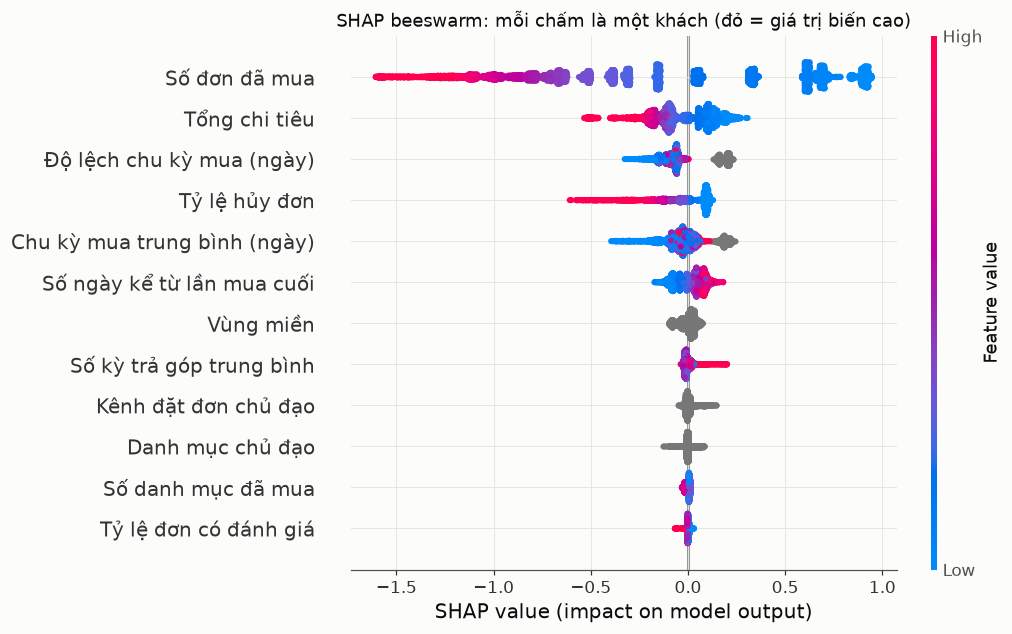

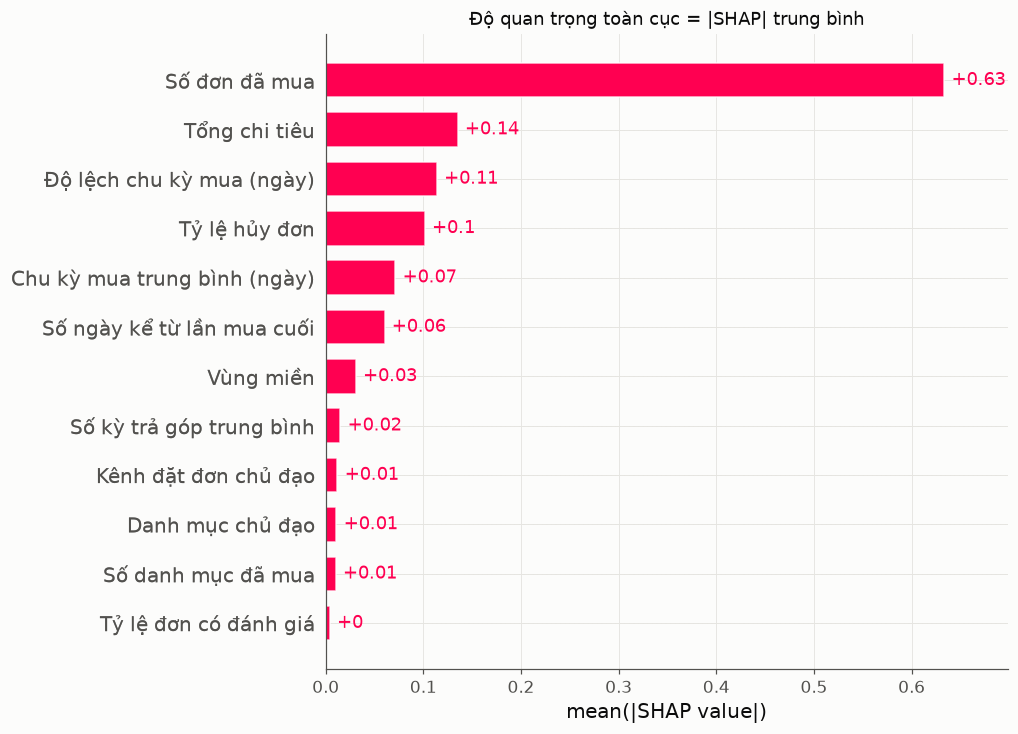

frequency           0.6334
monetary            0.1351
std_gap_days        0.1138
cancel_rate         0.1014
mean_gap_days       0.0713
recency_days        0.0603
region              0.0308
avg_installments    0.0150
main_source         0.0121
main_category       0.0110
n_categories        0.0102
review_rate         0.0042
dtype: float64

In [2]:
fig = plt.figure(); shap.plots.beeswarm(sv, max_display=12, show=False); plt.title("SHAP beeswarm: mỗi chấm là một khách (đỏ = giá trị biến cao)")
viz.save(plt.gcf(), "06_shap_beeswarm"); plt.show()
fig = plt.figure(); shap.plots.bar(sv, max_display=12, show=False); plt.title("Độ quan trọng toàn cục = |SHAP| trung bình")
viz.save(plt.gcf(), "06_shap_bar"); plt.show()
imp = pd.Series(np.abs(sv.values).mean(0), index=F).sort_values(ascending=False); imp.round(4)

## 2. PDP cho 3 biến quan trọng nhất

Đường cong trung bình dự đoán churn (xác suất thô) khi thay đổi một biến, giữ nguyên các biến còn lại ở giá trị thật của từng khách.

['frequency', 'monetary', 'std_gap_days']


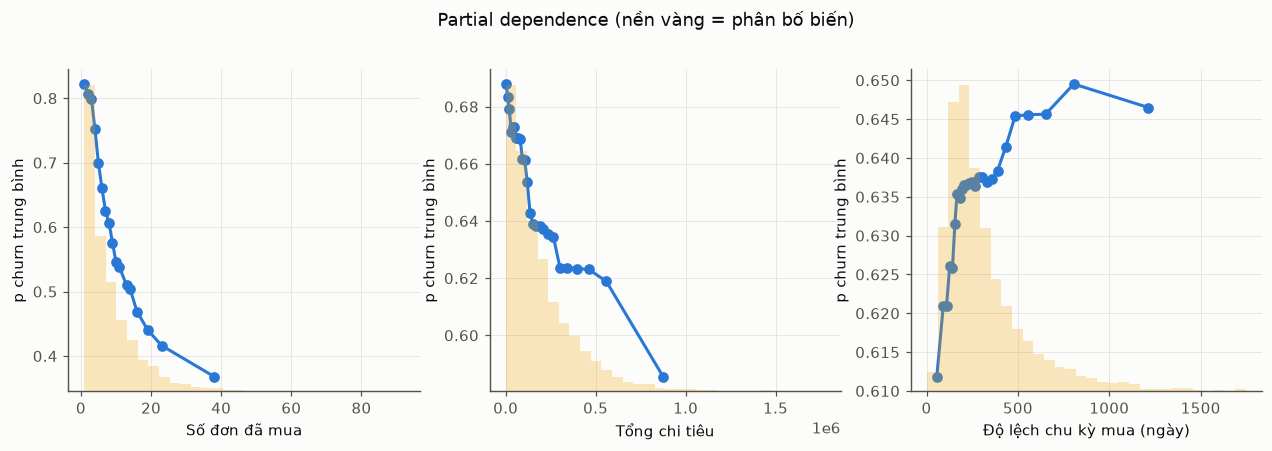

In [3]:
top3 = list(imp.index[:3]); print(top3)
Xs = samp[F].copy()
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, f in zip(ax, top3):
    grid = np.unique(np.nanpercentile(Xs[f], np.linspace(1, 99, 25)))
    pd_ = []
    for g in grid:
        d = Xs.copy(); d[f] = g; pd_.append(cm.predict_raw(d).mean())
    a.plot(grid, pd_, "o-", color=viz.C[0]); a.set_xlabel(LABELS[f][0]); a.set_ylabel("p churn trung bình")
    a2 = a.twinx(); a2.hist(Xs[f].dropna(), bins=30, color=viz.C[3], alpha=.25); a2.set_yticks([]); a2.grid(False)
fig.suptitle("Partial dependence (nền vàng = phân bố biến)", y=1.02); viz.save(fig, "06_pdp"); plt.show()

## 3. SHAP cục bộ: 3 khách đại diện

Chọn từ validation: (a) khách rủi ro cao nhất nhóm "đoán đúng là churn", (b) khách rủi ro thấp được đoán đúng là quay lại, (c) một ca **bỏ sót**: model báo an toàn nhưng khách bỏ đi.

(a) rủi ro cao, đúng | id 82764 | p = 0.942 | thực tế churn = 1
    Số đơn đã mua = 1 → tăng rủi ro (+0.92)
    Chu kỳ mua trung bình (ngày) = không có → tăng rủi ro (+0.21)
    Độ lệch chu kỳ mua (ngày) = không có → tăng rủi ro (+0.21)


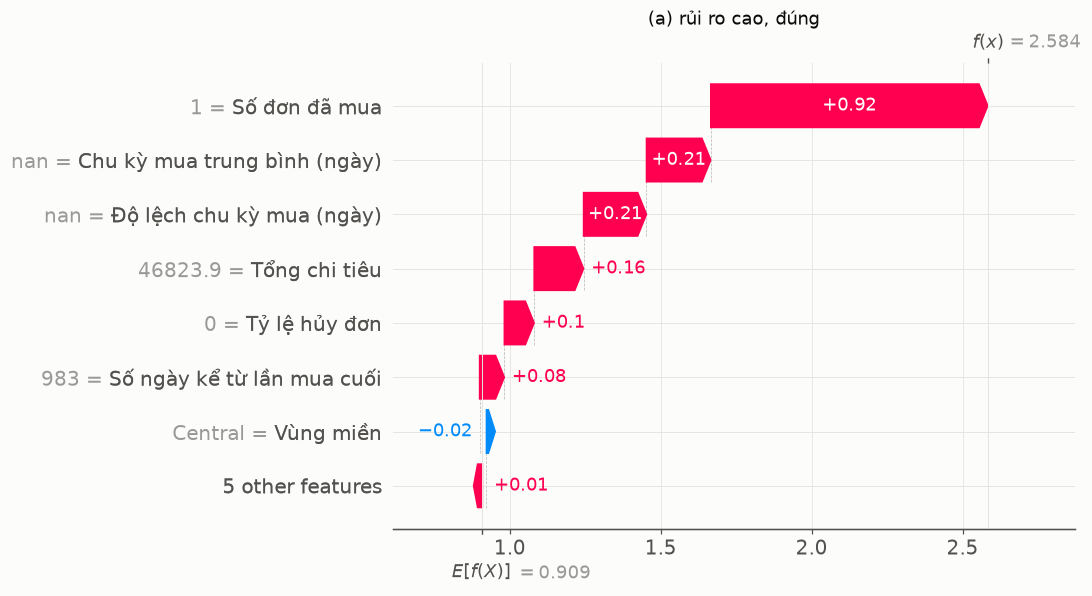

(b) rủi ro thấp, đúng | id 107302 | p = 0.147 | thực tế churn = 0
    Số đơn đã mua = 39 → giảm rủi ro (-1.57)
    Tổng chi tiêu = 1,192,174 → giảm rủi ro (-0.51)
    Chu kỳ mua trung bình (ngày) = 75 → giảm rủi ro (-0.33)


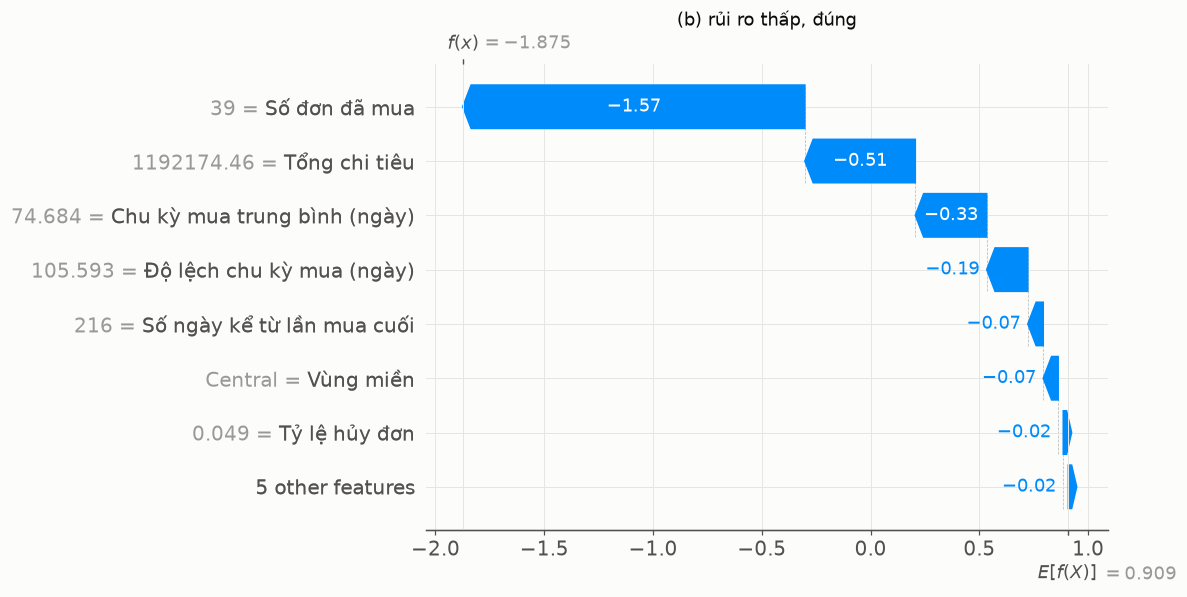

(c) bỏ sót (FN) | id 136225 | p = 0.192 | thực tế churn = 1
    Số đơn đã mua = 37 → giảm rủi ro (-1.50)
    Chu kỳ mua trung bình (ngày) = 82 → giảm rủi ro (-0.30)
    Tổng chi tiêu = 578,155 → giảm rủi ro (-0.26)


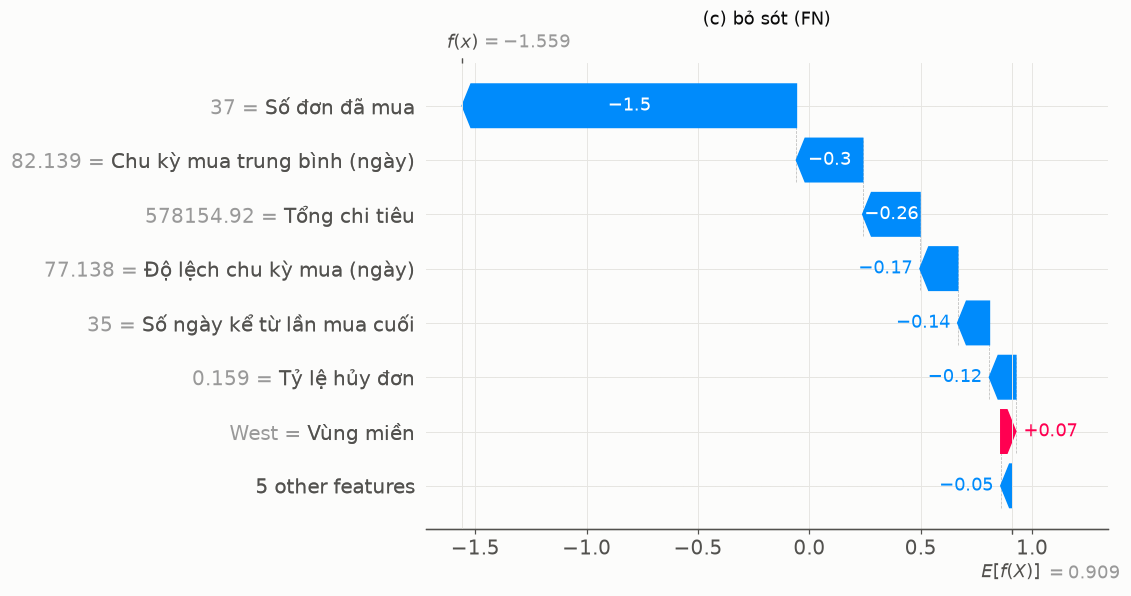

In [4]:
def pick(mask, order):
    return va[mask].sort_values("p", ascending=order).index[len(va[mask]) // 20]  # phân vị 5% để tránh ca cực đoan
cases = {"(a) rủi ro cao, đúng": pick((y == 1) & (va.p > TH), False), "(b) rủi ro thấp, đúng": pick((y == 0) & (va.p < TH), True),
         "(c) bỏ sót (FN)": pick((y == 1) & (va.p < TH), True)}
for k, i in cases.items():
    row = va.loc[[i]]
    print(k, "| id", i, "| p =", round(float(row.p.iloc[0]), 3), "| thực tế churn =", int(row.churn.iloc[0]))
    for r in cm.top_reasons(row)[0]: print("   ", r["label"], "=", r["value"], "→", r["effect"], f"({r['contribution']:+.2f})")
    e = ex(row[F]); e = e[..., 1] if e.values.ndim == 3 else e; e.feature_names = [LABELS[f][0] for f in F]
    shap.plots.waterfall(e[0], max_display=8, show=False); plt.title(k)
    viz.save(plt.gcf(), "06_waterfall_" + k[1]); plt.show()

## 4. Chân dung ca bỏ sót (FN) và báo nhầm (FP)

Ngưỡng 0,42 (F1 tối ưu ở Task 6). FN = thực tế churn nhưng điểm dưới ngưỡng; FP = điểm trên ngưỡng nhưng khách quay lại.

In [5]:
va["nhóm"] = np.select([(y == 1) & (va.p >= TH), (y == 1), (y == 0) & (va.p >= TH)], ["TP (đoán đúng churn)", "FN (bỏ sót)", "FP (báo nhầm)"], "TN (đoán đúng quay lại)")
cols = ["p", "frequency", "recency_days", "monetary", "mean_gap_days", "cancel_rate", "n_categories", "avg_installments", "orders_12m"]
prof = va.groupby("nhóm")[cols].median(); prof.insert(0, "số khách", va.nhóm.value_counts()); prof.round(3)

,số khách,p,frequency,recency_days,monetary,mean_gap_days,cancel_rate,n_categories,avg_installments,orders_12m
nhóm,,,,,,,,,,
FN (bỏ sót),2114,0.356,21.0,187.0,491085.19,133.437,0.083,3.0,3.448,1.0
FP (báo nhầm),12568,0.625,8.0,447.0,180945.84,302.143,0.067,2.0,3.333,0.0
TN (đoán đúng quay lại),4607,0.330,23.0,189.0,534389.82,121.609,0.085,3.0,3.436,1.0
TP (đoán đúng churn),33482,0.788,4.0,553.0,90432.48,439.000,0.000,2.0,3.125,0.0


In [6]:
fn, fp = va[va.nhóm.str.startswith("FN")], va[va.nhóm.str.startswith("FP")]
print(f"FN: {len(fn)} khách ({len(fn)/y.sum():.1%} số khách churn). FP: {len(fp)} ({len(fp)/(1-y).sum():.1%} số khách quay lại).")
print("Tỷ lệ khách 1 đơn ở: FN", round((fn.frequency == 1).mean(), 3), "| FP", round((fp.frequency == 1).mean(), 3), "| toàn bộ", round((va.frequency == 1).mean(), 3))
print("Tỷ lệ churn theo số đơn (validation):"); va.assign(f=va.frequency.clip(upper=6)).groupby("f").agg(khách=("p", "size"), churn_thực=("churn", "mean"), p_dự_đoán=("p", "mean")).round(3)

FN: 2114 khách (5.9% số khách churn). FP: 12568 (73.2% số khách quay lại).
Tỷ lệ khách 1 đơn ở: FN 0.0 | FP 0.029 | toàn bộ 0.113
Tỷ lệ churn theo số đơn (validation):


,khách,churn_thực,p_dự_đoán
f,,,
1,5941,0.939,0.935
2,5578,0.881,0.891
3,4966,0.836,0.841
4,4251,0.797,0.792
5,3741,0.745,0.739
6,28294,0.522,0.522


## 5. Hiệu năng theo nhóm

Kiểm tra model có hoạt động đều giữa các nhóm hay không (các biến này **không** nằm trong model, trừ `region`). Với mỗi nhóm: PR-AUC, ROC-AUC, tỷ lệ churn thực và xác suất dự đoán trung bình (chênh nhiều = hiệu chỉnh lệch cho nhóm đó).

In [7]:
rows = []
for g in ["age_group", "gender", "region", "acquisition_channel"]:
    for k, d in va.groupby(g, observed=True):
        if len(d) < 300 or d.churn.nunique() < 2: continue
        rows.append(dict(biến=g, nhóm=k, n=len(d), churn_thực=d.churn.mean(), p_TB=d.p.mean(), lệch=d.p.mean() - d.churn.mean(),
                         PR_AUC=AP(d.churn, d.p), ROC_AUC=ROC(d.churn, d.p)))
grp = pd.DataFrame(rows); grp.round(3)

,biến,nhóm,n,churn_thực,p_TB,lệch,PR_AUC,ROC_AUC
0,age_group,18-24,7328,0.679,0.676,-0.003,0.854,0.749
1,age_group,25-34,15619,0.676,0.676,0.000,0.865,0.765
2,age_group,35-44,13864,0.671,0.674,0.003,0.856,0.758
3,age_group,45-54,10026,0.671,0.671,0.000,0.857,0.758
4,age_group,55+,5934,0.678,0.674,-0.004,0.865,0.758
5,gender,Female,25836,0.676,0.674,-0.002,0.861,0.759
6,gender,Male,24910,0.673,0.675,0.002,0.858,0.759
7,gender,Non-binary,2025,0.673,0.676,0.002,0.859,0.753
8,region,Central,17156,0.692,0.694,0.002,0.877,0.772
9,region,East,26038,0.690,0.694,0.003,0.854,0.740


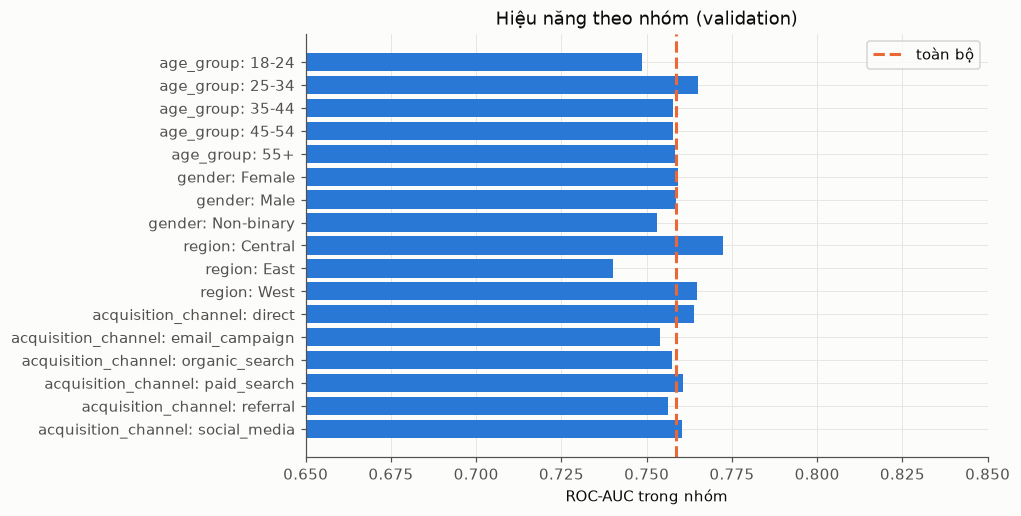

ROC-AUC min/max giữa các nhóm: 0.74 0.772 | |lệch| lớn nhất: 0.014


In [8]:
fig, ax = plt.subplots(figsize=(8, 5)); lab = grp.biến + ": " + grp.nhóm.astype(str)
ax.barh(lab, grp.ROC_AUC, color=viz.C[0]); ax.axvline(ROC(y, va.p), color=viz.C[1], ls="--", label="toàn bộ"); ax.set_xlim(0.65, 0.85); ax.legend()
ax.set_xlabel("ROC-AUC trong nhóm"); ax.set_title("Hiệu năng theo nhóm (validation)"); ax.invert_yaxis()
viz.save(fig, "06_by_group"); plt.show()
print("ROC-AUC min/max giữa các nhóm:", grp.ROC_AUC.min().round(3), grp.ROC_AUC.max().round(3), "| |lệch| lớn nhất:", grp.lệch.abs().max().round(3))

## 6. `top_reasons`: hàm cho web

`churn_model.ChurnModel.top_reasons(X, k=3)` trả về, cho mỗi khách, 3 biến tác động mạnh nhất (theo |đóng góp log-odds|) kèm giá trị và hướng (tăng/giảm rủi ro). Dùng `booster.predict(pred_contrib=True)` của LightGBM nên web không cần cài `shap`. Kiểm bằng `src/test_churn_model.py` (tổng đóng góp = log-odds của model).

In [9]:
ex_rows = va.sample(3, random_state=1)
for i, r in zip(ex_rows.index, cm.top_reasons(ex_rows)):
    print(i, round(float(va.p[i]), 3), [(x["label"], x["value"], x["effect"]) for x in r])

72317 0.575 [('Số đơn đã mua', '10', 'giảm rủi ro'), ('Tổng chi tiêu', '297,340', 'giảm rủi ro'), ('Tỷ lệ hủy đơn', '0%', 'tăng rủi ro')]
28878 0.583 [('Số đơn đã mua', '9', 'giảm rủi ro'), ('Tỷ lệ hủy đơn', '18%', 'giảm rủi ro'), ('Tổng chi tiêu', '208,143', 'giảm rủi ro')]
53463 0.916 [('Số đơn đã mua', '2', 'tăng rủi ro'), ('Tổng chi tiêu', '8,308', 'tăng rủi ro'), ('Độ lệch chu kỳ mua (ngày)', 'không có', 'tăng rủi ro')]


## 7. Nhận xét

- **Một biến gánh gần hết:** `frequency` có |SHAP| trung bình 0,63, gấp 4,7 lần biến thứ hai (`monetary` 0,14). Khách mua càng nhiều đơn càng ít churn, đơn điệu và mạnh: tỷ lệ churn thật 94% (1 đơn) giảm còn 52% (≥ 6 đơn), và xác suất dự đoán khớp sát từng mức.
- **`std_gap_days`, `mean_gap_days`:** chủ yếu có ích để phân biệt khách 1 đơn (không có chu kỳ, giá trị "không có" tăng rủi ro) với khách đã có nhịp mua; chu kỳ dài thì tăng rủi ro.
- **Điểm cần cẩn thận với `cancel_rate`:** đứng thứ tư toàn cục, nhưng chiều tác động trái trực giác: khách **từng hủy đơn** ít churn hơn 6–11 điểm % ở mọi mức số đơn (ví dụ 3 đơn: 78% so với 86%). Có thể hủy đơn là dấu hiệu khách còn tương tác nhiều, hoặc là đặc điểm do dữ liệu tự sinh, không phải quan hệ nhân quả. Hệ quả: **không nên hiển thị "tỷ lệ hủy đơn" như một lý do trên web** và không nên khuyên hành động dựa trên nó (ví dụ ca đại diện ở mục 6 có "hủy 0% → tăng rủi ro"). Đây là ứng viên để loại khỏi `top_reasons` hoặc để bỏ khỏi bản web, đã nêu ở Task 5.
- **Ca bỏ sót (FN, 2.114 khách, chỉ 5,9% số khách churn):** toàn là khách rất gắn bó (trung vị 21 đơn, 1 đơn trong 12 tháng gần nhất), gần giống nhóm TN (23 đơn). Không có đặc điểm riêng để phân biệt: đó là những khách "đang hoạt động" bất ngờ dừng lại. Với dữ liệu hiện có thì đây là sai số không thể tránh (cộng thêm nhiễu của nhãn 12 tháng, Task 2).
- **Ca báo nhầm (FP, 12.568 khách, 73% số khách quay lại ở ngưỡng 0,42):** khách số đơn trung bình (8 đơn), chu kỳ mua dài (302 ngày), lâu chưa mua (447 ngày). Chu kỳ dài nên 12 tháng chưa mua là bình thường với họ, nhưng model coi là rủi ro. Phần lớn FP này do ngưỡng thấp (0,42): khi 65% khách là churn, ngưỡng F1 tối ưu thiên về bắt hết. Nên xếp hạng theo `p_churn × CLV` thay vì cắt ngưỡng.
- **Công bằng giữa các nhóm:** tuổi, giới tính, kênh khách đến: ROC-AUC trong khoảng 0,749–0,765 và lệch hiệu chỉnh |p̄ − tỷ lệ thật| ≤ 0,006, tức model đối xử đồng đều. Khác biệt duy nhất đáng kể là vùng: West churn thấp hơn (60% so với 69%) và PR-AUC thấp hơn (0,831), nhưng ROC-AUC vẫn bình thường (0,765); chỉ là tỷ lệ nền khác. Mức lệch hiệu chỉnh lớn nhất là −0,014 ở West (dự đoán thấp hơn thực tế 1,4 điểm %), chấp nhận được.
- **`top_reasons`:** hoạt động, trả 3 lý do kèm giá trị và hướng; được kiểm bằng `src/test_churn_model.py` (3 test qua).